### Simple Regression Exapmle

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplotpl as plt
import seaborn as sns


In [3]:
df=pd.read_csv("SAT_scores.csv")
df.head()

,SAT Score,GPA
0,1600,4.0
1,1593,4.0
2,1587,4.0
3,1580,4.0
4,1573,4.0


### exploratory data analysis

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   SAT Score  181 non-null    int64  
 1   GPA        181 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 3.0 KB


In [6]:
df.describe()

,SAT Score,GPA
count,181.000000,181.000000
mean,1000.000000,2.617901
std,349.293573,1.559243
min,400.000000,0.000000
25%,700.000000,1.390000
50%,1000.000000,3.370000
75%,1300.000000,3.970000
max,1600.000000,4.000000


In [7]:
df.corr()

,SAT Score,GPA
SAT Score,1.000000,0.923073
GPA,0.923073,1.000000


<Axes: >

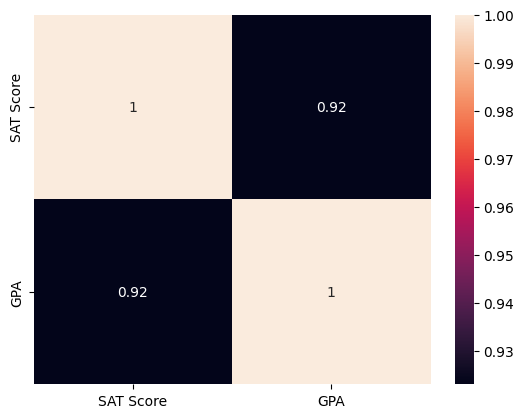

In [10]:
sns.heatmap(df.corr(),annot=True)

### find the relationship is linear or non linear

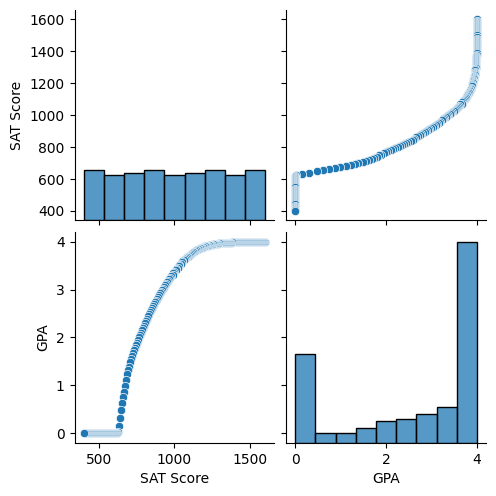

In [12]:
sns.pairplot(df)

### slit the data

In [14]:
X=df.drop('GPA',axis=1)

y=df['GPA']

from sklearn.model_selection import train_test_split
#train size deremine the train set
#randam_state it is used to split the same data ererytime
X_train,X_test,y_train,y_test=train_test_split(
    X,y,train_size=0.7, test_size=0.3,random_state=42)
X_train

### data pre-processing

In [19]:
####-science the data is already is grete shape, noneed to shape

### train the model

In [20]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [22]:
X_train.shape

(126, 1)

In [23]:
X_train.

(126, 1)

In [34]:
y_pred=model.predict(X_test)

In [37]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
print(f"mean absolute error={mae:2f}")

mean absolute error=0.520135


In [39]:
from sklearn.metrics import  mean_absolute_percentage_error
mape=mean_absolute_percentage_error(y_test,y_pred)
print(f"mean_absolute_percentage_error={mape}")

mean_absolute_percentage_error=503223947728665.25


In [40]:
from sklearn.metrics import mean_squared_error
mse=mean_squared_error(y_test,y_pred)
print(f"mean squared error={mse}")

mean squared error=0.33122667351205903


In [41]:
from sklearn.metrics import root_mean_squared_error
rmse=root_mean_squared_error(y_test,y_pred)
print(f"root mean squared error={rmse}")

root mean squared error=0.57552295654653


In [44]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
print(f"r2 score={r2:.2f}")

r2 score=0.87


In [ ]:
metrics=[
    {"MAE":mae},
    ]

### inferene the model

In [26]:
# predict GPA of a student having SAT as 10000
result=model.predict([[1000],[1500]])
result

C:\Users\neham\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([2.62909018, 4.67637706])

In [27]:
# in general, the model is represented as
# y=B0+B1X1+E
# the B0 is a constant
B0=model.intercept_
print(B0)

-1.4654835717229249


In [28]:
B1=model.coef_[0]
B1

0.0040945737526873385

In [32]:
SAT_SCORE=1000
y=B0+B1*SAT_SCORE
print(y)

2.629090180964414


In [31]:
SAT_SCORE=1500
y=B0+B1*SAT_SCORE
print(y)

4.676377057308083


In [47]:
import pickle
file=open("sat_model.pkl","wb")
pickle.dump(model,file)
file.close()